<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/14_CNN_P6_(LeNet).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Convolutional Neural Networks (LeNet)

We have now learned the main building blocks of a convolutional neural network (CNN):

- Convolution layers extract features from images.
- Padding preserves spatial dimensions.
- Stride controls how the filter moves across the image.
- Pooling reduces the spatial size of feature maps.
- Multiple channels allow the network to learn many features simultaneously.

These components are combined to form complete CNN architectures. One of the earliest and most influential CNNs is **LeNet**, proposed by Yann LeCun in the late 1980s for handwritten digit recognition.

## LeNet

LeNet-5 is one of the earliest convolutional neural networks (CNNs). It combines the main building blocks introduced in the previous sections—convolution, pooling, and fully connected layers—into a complete architecture for image classification.

The network consists of two main parts:

- **Convolutional block:** extracts features using convolution and pooling layers.
- **Dense block:** uses fully connected layers to classify the extracted features.

The following figure illustrates the overall architecture of LeNet.

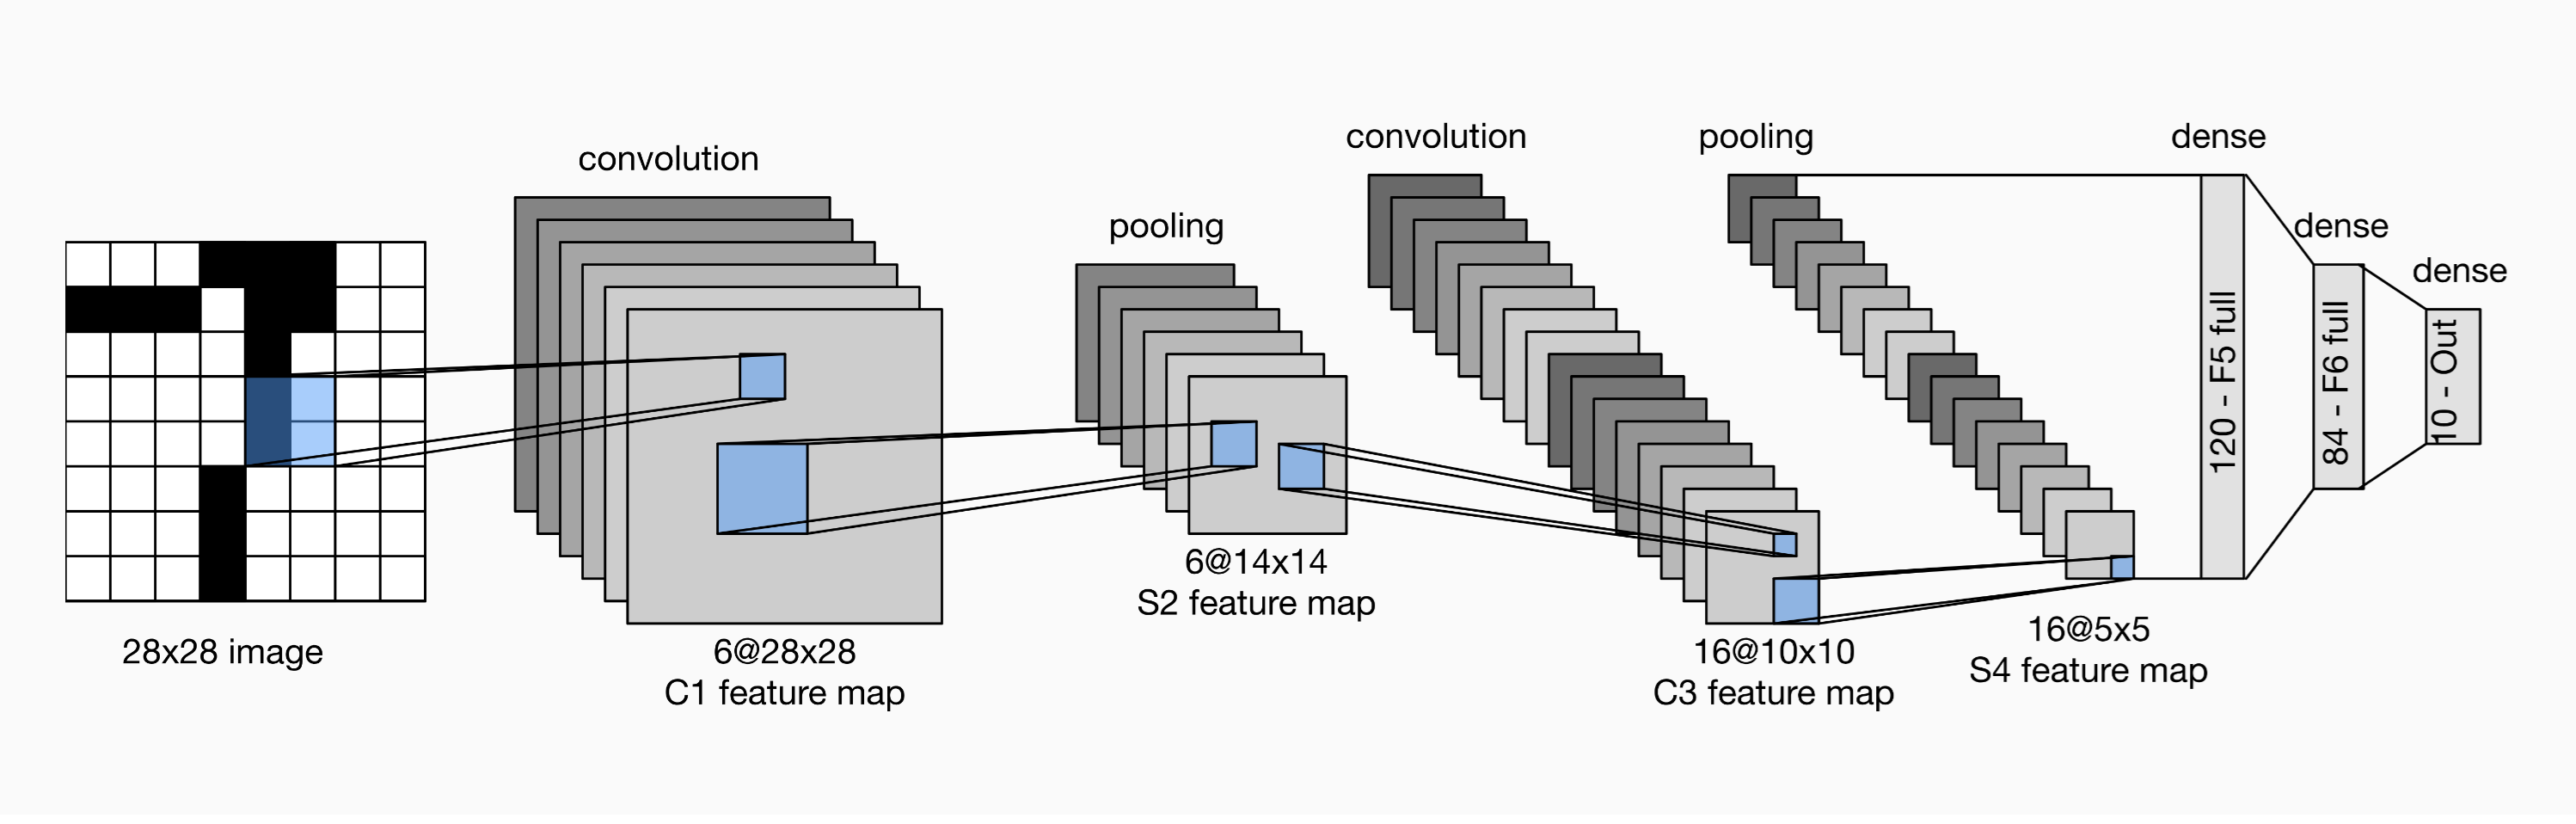

### Understanding the Architecture

LeNet processes an input image in several stages:

- The **first convolutional layer** extracts simple features such as edges and textures.
- **Average pooling** reduces the spatial dimensions while retaining the most important information.
- The **second convolutional layer** learns more complex patterns from the pooled feature maps.
- A second **pooling layer** further reduces the feature map size.
- The **Flatten** layer converts the 3D feature maps into a 1D feature vector.
- Three **fully connected (dense) layers** perform the final classification, producing one output for each of the 10 Fashion-MNIST classes.

In [ ]:
!pip install --q D2l --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 7.4 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l

In [ ]:
# Define the LeNet-5 convolutional neural network.
class LeNet(d2l.Classifier):
    """The LeNet-5 model."""

    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()

        # Build the network as a sequence of layers.
        self.net = tf.keras.models.Sequential([

            # First convolution:
            # Learn 6 feature maps using 5×5 filters.
            # SAME padding preserves the spatial dimensions.
            tf.keras.layers.Conv2D(
                filters=6,
                kernel_size=5,
                activation='sigmoid',
                padding='same'
            ),

            # Reduce the height and width by half.
            tf.keras.layers.AvgPool2D(
                pool_size=2,
                strides=2
            ),

            # Learn 16 higher-level feature maps.
            tf.keras.layers.Conv2D(
                filters=16,
                kernel_size=5,
                activation='sigmoid'
            ),

            # Further reduce the spatial dimensions.
            tf.keras.layers.AvgPool2D(
                pool_size=2,
                strides=2
            ),

            # Convert the feature maps into a 1D feature vector.
            tf.keras.layers.Flatten(),

            # Fully connected layer with 120 neurons.
            tf.keras.layers.Dense(
                120,
                activation='sigmoid'
            ),

            # Fully connected layer with 84 neurons.
            tf.keras.layers.Dense(
                84,
                activation='sigmoid'
            ),

            # Output layer (one neuron per class).
            tf.keras.layers.Dense(num_classes)
        ])

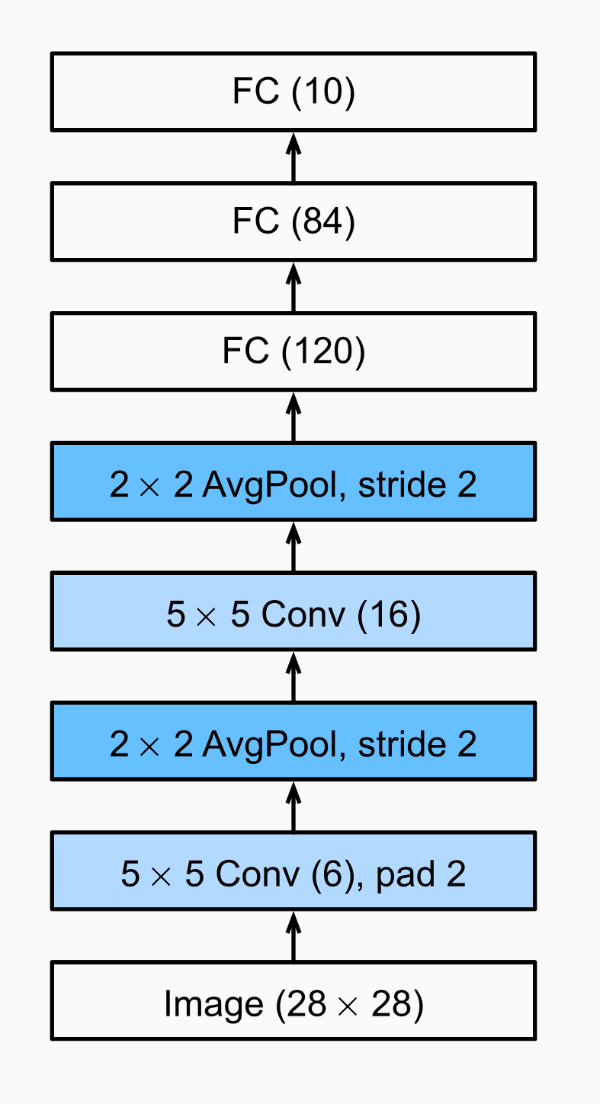

### Implementing LeNet

The following code implements the LeNet-5 architecture using TensorFlow's `Sequential` API. Each layer corresponds directly to the architecture shown above, beginning with convolution and pooling layers for feature extraction, followed by fully connected layers for classification.

In [ ]:
# Add a helper method to the Classifier class that prints
# the output shape after each layer in the network.
@d2l.add_to_class(d2l.Classifier)
def layer_summary(self, X_shape):

    # Create a random input tensor with the specified shape.
    X = tf.random.normal(X_shape)

    # Pass the input through each layer one at a time.
    for layer in self.net.layers:

        # Compute the output of the current layer.
        X = layer(X)

        # Display the layer type and its output shape.
        print(layer.__class__.__name__, "output shape:\t", X.shape)


# Create a LeNet model.
model = LeNet()

# Print how the tensor shape changes as it passes
# through each layer of the network.
#
# Input shape:
# (batch_size, height, width, channels)
model.layer_summary((1, 28, 28, 1))

Conv2D output shape:	 (1, 28, 28, 6)
AveragePooling2D output shape:	 (1, 14, 14, 6)
Conv2D output shape:	 (1, 10, 10, 16)
AveragePooling2D output shape:	 (1, 5, 5, 16)
Flatten output shape:	 (1, 400)
Dense output shape:	 (1, 120)
Dense output shape:	 (1, 84)
Dense output shape:	 (1, 10)


### Understanding the Layer Summary

The layer summary shows how the shape of the data changes as it passes through each layer of LeNet.

- The **convolutional layers** increase the number of feature maps while extracting image features.
- The **pooling layers** reduce the height and width of the feature maps.
- The **Flatten** layer converts the feature maps into a one-dimensional vector.
- The **Dense** layers gradually reduce the feature vector until the final layer produces one output for each of the 10 classes.

## Training LeNet

After defining the LeNet architecture, we can train the model on the Fashion-MNIST dataset.

The following example creates the dataset, initializes the LeNet model, and trains it for **10 epochs** using mini-batch stochastic gradient descent. During training, the loss and validation accuracy are recorded to monitor the model's performance.

## Training LeNet

After defining the LeNet architecture, the model can be trained on the Fashion-MNIST dataset.

The following code performs four steps:

1. Creates a trainer that will optimize the model for **10 epochs**.
2. Loads the Fashion-MNIST dataset with a **batch size of 128**.
3. Initializes the LeNet model and specifies the **sparse categorical cross-entropy** loss function, which is appropriate because the dataset labels are integer class IDs (0–9).
4. Trains the network and records the training and validation performance after each epoch.

During training, the model learns the convolution and dense layer weights using mini-batch gradient descent. As training progresses, the training loss should decrease while the validation accuracy should increase, indicating that the model is learning useful image features.

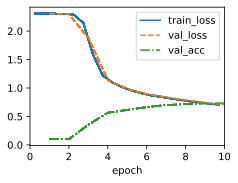

In [ ]:
# Create the trainer.
trainer = d2l.Trainer(max_epochs=10)

# Load Fashion-MNIST.
data = d2l.FashionMNIST(batch_size=128)

# Use sparse cross-entropy because labels are integer class IDs
# with shape (batch_size,), such as [2, 7, 1, ...].
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="sum_over_batch_size"
)

with d2l.try_gpu():

    # Create the LeNet model.
    model = LeNet(lr=0.1)

    # D2L calls loss(y_hat, y), but Keras expects
    # loss(y_true, y_pred), so reverse the arguments.
    model.loss = lambda y_hat, y: loss_fn(
        tf.reshape(y, (-1,)),
        tf.reshape(y_hat, (-1, y_hat.shape[-1]))
    )

    # Train the model.
    trainer.fit(model, data)

### Interpreting the Training Curves

The training results show that the loss decreases steadily over the training epochs, indicating that the network is learning meaningful image features.

At the same time, the validation accuracy increases as training progresses, demonstrating improved classification performance on unseen data.

The close agreement between the training and validation losses suggests that the model is learning effectively without obvious signs of severe overfitting during the first 10 epochs.

### Training Results

The training process reports the loss and validation accuracy after each epoch.

In general:

- **Training loss** should decrease as the model learns.
- **Validation accuracy** should increase, indicating better classification performance on unseen images.
- If the validation accuracy stops improving while the training loss continues to decrease, the model may be starting to overfit.

These learning curves provide a quick way to evaluate whether the network is training successfully.

> **Note:** The D2L framework and Keras expect the loss function arguments in different orders. D2L calls the loss function as `loss(predictions, labels)`, whereas Keras expects `loss(labels, predictions)`. Therefore, a small wrapper function is used to reverse the argument order before computing the loss.

## Summary

In this section, we combined the concepts introduced throughout the chapter to build and train the **LeNet-5** convolutional neural network.

LeNet demonstrates how the major CNN components work together:

- **Convolutional layers** extract increasingly complex image features.
- **Pooling layers** reduce the spatial dimensions of feature maps.
- **Flatten** converts the extracted feature maps into a feature vector.
- **Fully connected layers** use these learned features to classify the input image.

Finally, the model was trained on the Fashion-MNIST dataset, where the decreasing training loss and improving validation accuracy demonstrated that the network successfully learned to recognize clothing images.